# Employee scheduling

A ward runs around the clock, and someone has to be on it for every morning, evening and night
shift of the next two weeks. Each shift needs a qualified nurse, nobody may work too long or rest too
little, and every nurse has days they cannot work and days they would rather not. The question is
**who works which shift**.

In this notebook you will:

1. describe a two-week ward roster as Python objects,
2. solve it and read the result as a roster grid,
3. check the result yourself, without trusting the solver's score,
4. change the rules so that night shifts are shared fairly,
5. lose nurses and see what the roster gives up,
6. spend more search time on a result, one round after another,
7. repair a roster when a nurse calls in sick, keeping what already happened.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from optimaru import employee_scheduling as es
from optimaru.employee_scheduling.models import (
    AssignmentCostRule, BalanceLocationRule, MaxConsecutiveDaysRule, MaxWeeklyMinutesRule, ScheduleRequest,
    SchedulingInput, ShiftModel, SolverSettings, UnassignedShiftRule, WorkerModel, default_rules,
    solve_request, with_initial_solution,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the ward

Three kinds of objects make up a roster. All times are **integer minutes from day 0, 00:00**, and
`es.minutes(day, hour)` builds one. A date is a day number.

| Object | What it holds |
| --- | --- |
| `Employee` | one nurse: skills, plus unavailable, undesired and desired days |
| `Shift` | one slot to fill: start, end, a location string, the required skill |
| `EmployeeSchedule` | the employees and the shifts, and the score once solved |

`location` can hold a site, a team or a shift type, and rules that talk about a location read this
string. Here it holds the shift type.

The ward below is fictional: 13 nurses, 5 of them qualified to lead a shift as charge nurse. Day 0 is
a Monday. Weekdays need 3 + 3 + 2 nurses and weekends 2 + 2 + 2, and the first slot of every
shift is the charge nurse's.

In [2]:
DAYS = 14
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SHIFT_HOURS = 8
START_HOUR = {"Morning": 7, "Evening": 15, "Night": 23}
SHIFT_TYPES = list(START_HOUR)

rng = np.random.default_rng(11)
NAMES = ["Ada", "Bram", "Cleo", "Dov", "Esme", "Finn", "Gia", "Hugo", "Iris", "Jonas", "Kaia", "Liam", "Mira"]
nurses = []
for i, name in enumerate(NAMES):
    days = [int(d) for d in rng.permutation(DAYS)]
    nurses.append(es.Employee(
        name,
        skills={"Nurse", "Charge"} if i < 5 else {"Nurse"},
        unavailable_dates=set(days[:2]),
        undesired_dates=set(days[2:4]),
        desired_dates=set(days[4:6]),
    ))


def demand(day, shift_type):
    if shift_type == "Night":
        return 2
    return 2 if day % 7 >= 5 else 3


def make_shifts():
    """Fresh, unassigned shifts. Solvers work in place, so each experiment gets its own."""
    shifts = []
    for day in range(DAYS):
        for shift_type in SHIFT_TYPES:
            for slot in range(demand(day, shift_type)):
                start = es.minutes(day, START_HOUR[shift_type])
                shifts.append(es.Shift(f"D{day:02d}-{shift_type[0]}{slot}", start, start + SHIFT_HOURS * 60,
                                       shift_type, "Charge" if slot == 0 else "Nurse"))
    return shifts


shifts = make_shifts()
print(f"{len(nurses)} nurses, {len(shifts)} shifts, {sum(s.required_skill == 'Charge' for s in shifts)} charge slots")
print(f"at 40 hours a week the nurses can work {len(nurses) * 2 * 40 // SHIFT_HOURS} shifts in total")

13 nurses, 104 shifts, 42 charge slots
at 40 hours a week the nurses can work 130 shifts in total


Preferences and absences decide most of the roster, so they are worth seeing before solving.

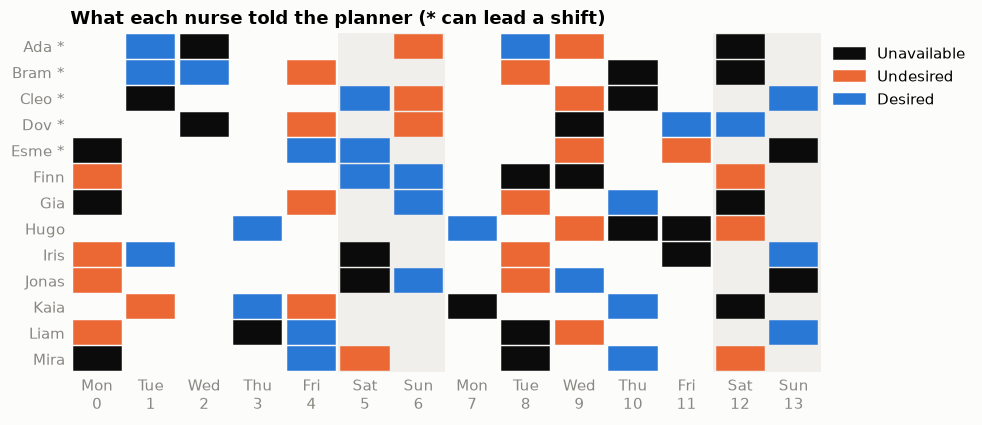

In [3]:
def shade_weekends(ax):
    for day in range(DAYS):
        if day % 7 >= 5:
            ax.axvspan(day, day + 1, color="#f0efec", zorder=0, linewidth=0)


def day_axis(ax):
    ax.set_xticks(np.arange(DAYS) + 0.5, [f"{DAY_NAMES[d % 7]}\n{d}" for d in range(DAYS)])
    ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)


def nurse_labels(employees):
    return [f"{e.name} *" if "Charge" in e.skills else e.name for e in employees]


WISH_COLOR = {"Unavailable": "#0b0b0b", "Undesired": COLORS[1], "Desired": COLORS[0]}
fig, ax = plt.subplots(figsize=(8.8, 4))
shade_weekends(ax)
for row, nurse in enumerate(nurses):
    wishes = {"Unavailable": nurse.unavailable_dates, "Undesired": nurse.undesired_dates,
              "Desired": nurse.desired_dates}
    for wish, wish_days in wishes.items():
        for day in wish_days:
            ax.add_patch(plt.Rectangle((day + 0.06, row + 0.06), 0.88, 0.88, color=WISH_COLOR[wish]))
day_axis(ax)
ax.set(xlim=(0, DAYS), ylim=(len(nurses), 0), title="What each nurse told the planner (* can lead a shift)")
ax.set_yticks(np.arange(len(nurses)) + 0.5, nurse_labels(nurses))
ax.legend(handles=[Patch(color=WISH_COLOR[w], label=w) for w in WISH_COLOR], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

A rule list says what is scored. `default_rules()` gives eight rules: the required skill, no shift on
an unavailable day, no overlap, at most one shift per day, 10 hours of rest between shifts, the
undesired and desired days, and an even shift count. On top of those this ward needs every shift
filled, at most 5 days in a row, and at most 40 hours a week.

`Solver.solve` works in place. The score has two levels, compared in order:

- **hard**: broken must-rules, where `0` means the roster is feasible. Units vary by rule: one rule
  counts shifts, another counts minutes.
- **soft**: the nice-to-have rules. Minutes on a desired day add to it, minutes on an undesired day
  and uneven shift counts take from it, so a good roster can have a positive soft score.

A night shift runs across midnight, so it overlaps two dates and these rules count its minutes on
each date separately.

In [4]:
RULES = [
    *default_rules(),
    UnassignedShiftRule(),
    MaxConsecutiveDaysRule(value=5),
    MaxWeeklyMinutesRule(minutes=40 * 60),
]


def solve_roster(rules, staff=nurses, seconds=3.0, seed=42):
    config = es.SolverConfig()
    config.spent_limit_seconds = seconds
    config.random_seed = seed
    schedule = es.EmployeeSchedule(staff, make_shifts())
    calculator = es.DecomposedCalculator(rules)
    es.Solver(config).solve(schedule, calculator)
    return schedule, calculator


roster, calculator = solve_roster(RULES)

print("feasible:", roster.score.is_feasible())
print("score   :", roster.score.hard, "/", roster.score.soft)
for total in calculator.constraint_totals():
    if total["cost"]:
        print(f"  {total['name']}: {total['cost']:.1f}")

feasible: True
score   : 0 / 9537.17157
  Undesired day for employee: 2936.0
  Desired day for employee: -12476.0
  Balance employee shift assignments: 2.8


`constraint_totals()` explains the score: a positive cost is a penalty and a negative cost a reward.

### The roster

This is the page a ward manager would pin up. Each row is a nurse and each column a day. The block
underneath counts the nurses on each shift, and a mismatch with the demand would show in red.

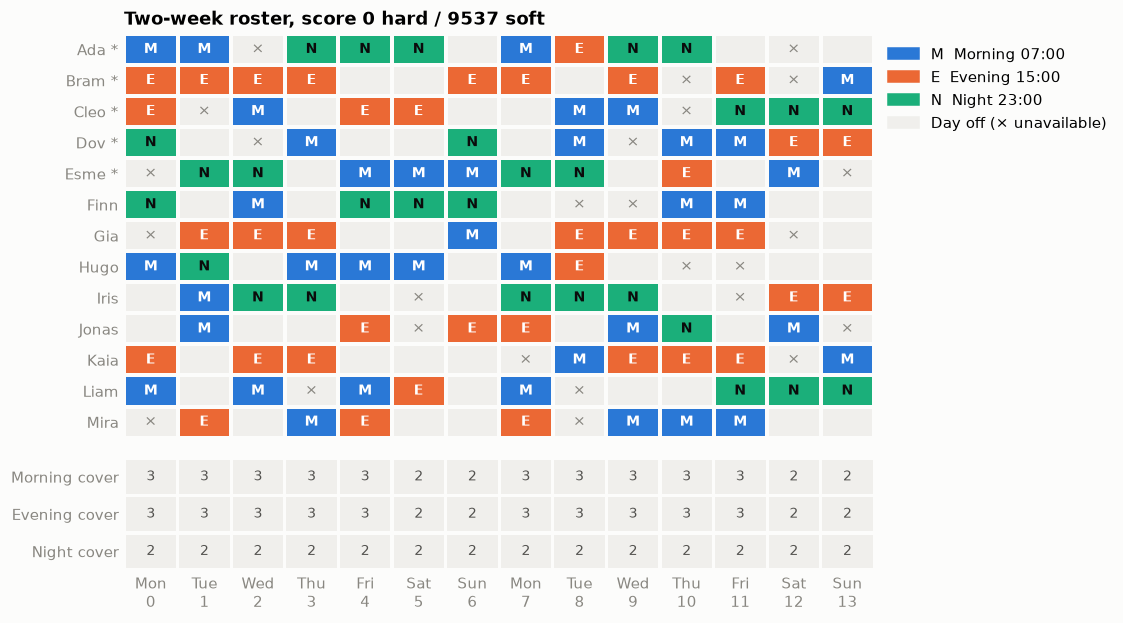

In [5]:
def roster_grid(schedule):
    """Row per nurse, column per day: index into SHIFT_TYPES, or -1 for a day off."""
    grid = np.full((len(schedule.employees), DAYS), -1)
    for shift, nurse in zip(schedule.shifts, schedule.assignment()):
        if nurse >= 0:
            grid[nurse, shift.start // es.MINUTES_PER_DAY] = SHIFT_TYPES.index(shift.location)
    return grid


SHIFT_COLOR = {"Morning": COLORS[0], "Evening": COLORS[1], "Night": COLORS[2]}
CELL_TEXT = {"Morning": "white", "Evening": "white", "Night": "#0b0b0b"}
OFF_COLOR = "#f0efec"


def draw_roster(schedule, title):
    grid = roster_grid(schedule)
    staff = schedule.employees
    fig, (ax, cover) = plt.subplots(
        2, 1, figsize=(8.8, 0.31 * len(staff) + 2.3), sharex=True, height_ratios=[len(staff), 3.6],
        gridspec_kw={"hspace": 0.08},
    )
    cmap = ListedColormap([OFF_COLOR, *SHIFT_COLOR.values()])
    ax.pcolormesh(grid, cmap=cmap, vmin=-1.5, vmax=2.5, edgecolors="#fcfcfb", linewidth=1.5)
    for row, nurse in enumerate(staff):
        for day in range(DAYS):
            if grid[row, day] >= 0:
                shift_type = SHIFT_TYPES[grid[row, day]]
                ax.text(day + 0.5, row + 0.5, shift_type[0], ha="center", va="center",
                        color=CELL_TEXT[shift_type], fontweight="bold", fontsize=9)
            elif day in nurse.unavailable_dates:
                ax.text(day + 0.5, row + 0.5, "×", ha="center", va="center", color=MUTED)
    ax.set_ylim(len(staff), 0)
    ax.set_yticks(np.arange(len(staff)) + 0.5, nurse_labels(staff))
    ax.tick_params(length=0, labelbottom=False)
    ax.set_title(title)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)

    for row, shift_type in enumerate(SHIFT_TYPES):
        for day in range(DAYS):
            count = int((grid[:, day] == row).sum())
            short = count != demand(day, shift_type)
            cover.add_patch(plt.Rectangle((day + 0.03, row + 0.05), 0.94, 0.9,
                                          color=COLORS[7] if short else OFF_COLOR, linewidth=0))
            cover.text(day + 0.5, row + 0.5, str(count), ha="center", va="center",
                       color="white" if short else INK, fontsize=9)
    cover.set_ylim(3, 0)
    cover.set_xlim(0, DAYS)
    cover.set_yticks(np.arange(3) + 0.5, [f"{t} cover" for t in SHIFT_TYPES])
    day_axis(cover)
    handles = [Patch(color=SHIFT_COLOR[t], label=f"{t[0]}  {t} {START_HOUR[t]:02d}:00") for t in SHIFT_TYPES]
    handles += [Patch(color=OFF_COLOR, label="Day off (× unavailable)")]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()


draw_roster(roster, f"Two-week roster, score {roster.score.hard} hard / {roster.score.soft:.0f} soft")

## 3. Check the result yourself

The answer is one number per shift: `assignment()` gives the nurse's index. That is enough to
recompute every hard rule with no solver code.

In [6]:
def check_roster(schedule):
    day_of = lambda minute: minute // es.MINUTES_PER_DAY
    staff, assignment = schedule.employees, schedule.assignment()
    worked = [[] for _ in staff]
    for shift, nurse in zip(schedule.shifts, assignment):
        if nurse >= 0:
            worked[nurse].append(shift)

    missing_skill = off_day = same_day = short_rest = long_runs = over_hours = 0
    for nurse, shifts_of_nurse in zip(staff, worked):
        shifts_of_nurse.sort(key=lambda s: s.start)
        missing_skill += sum(s.required_skill not in nurse.skills for s in shifts_of_nurse)
        off_day += sum(bool({day_of(s.start), day_of(s.end - 1)} & nurse.unavailable_dates) for s in shifts_of_nurse)
        same_day += sum(day_of(a.start) == day_of(b.start) for a, b in zip(shifts_of_nurse, shifts_of_nurse[1:]))
        short_rest += sum(b.start - a.end < 10 * 60 for a, b in zip(shifts_of_nurse, shifts_of_nurse[1:]))

        on_duty = {day_of(s.start) for s in shifts_of_nurse}
        run = 0
        for day in range(DAYS):
            run = run + 1 if day in on_duty else 0
            long_runs += run > 5
        for week in range(DAYS // 7):
            minutes = sum(s.end - s.start for s in shifts_of_nurse if day_of(s.start) // 7 == week)
            over_hours += minutes > 40 * 60

    return {
        "shifts with nobody on them": assignment.count(-1),
        "shifts without the required skill": missing_skill,
        "shifts touching an unavailable day": off_day,
        "two shifts starting on one day": same_day,
        "gaps under 10 hours of rest": short_rest,
        "days beyond 5 in a row": long_runs,
        "nurse-weeks over 40 hours": over_hours,
    }


for rule, count in check_roster(roster).items():
    print(f"{count:3d}  {rule}")

  0  shifts with nobody on them
  0  shifts without the required skill
  0  shifts touching an unavailable day
  0  two shifts starting on one day
  0  gaps under 10 hours of rest
  0  days beyond 5 in a row
  0  nurse-weeks over 40 hours


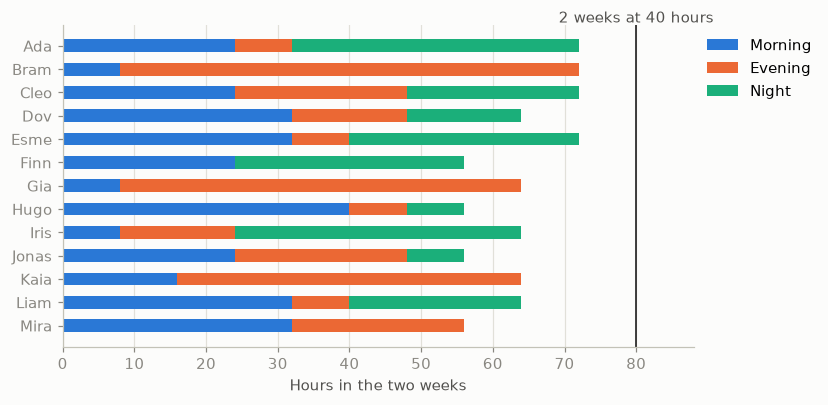

In [7]:
def hours_by_type(schedule):
    grid = roster_grid(schedule)
    return {t: (grid == i).sum(axis=1) * SHIFT_HOURS for i, t in enumerate(SHIFT_TYPES)}


fig, ax = plt.subplots(figsize=(7.4, 3.8))
left = np.zeros(len(nurses))
for shift_type, hours in hours_by_type(roster).items():
    ax.barh(NAMES, hours, left=left, height=0.55, color=SHIFT_COLOR[shift_type], label=shift_type)
    left += hours
ax.axvline(80, color="#0b0b0b", linewidth=1)
ax.text(80, -1.0, "2 weeks at 40 hours", ha="center", color=INK)
ax.invert_yaxis()
ax.set(xlim=(0, 88), xlabel="Hours in the two weeks")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

The rules above spread total hours, but nothing says the nights must be shared. Look at the green
segments: that is the next thing to fix.

## 4. Change the rules, not the solver

`list_constraints()` shows every rule this use case ships. Only the rules in your list are scored.

In [8]:
print(es.list_constraints())

['required_skill', 'unavailable_employee', 'overlapping_shift', 'one_shift_per_day', 'min_rest', 'undesired_day', 'desired_day', 'desired_shift', 'balance_assignments', 'max_consecutive_days', 'min_consecutive_days', 'max_consecutive_off', 'rest_after_consecutive_work', 'max_weekly_minutes', 'min_weekly_minutes', 'min_weekly_rest_days', 'assignment_cost', 'unassigned_shift', 'balance_min_max_gap', 'balance_weekly_minutes_gap', 'shift_coverage', 'location_run', 'rest_after_location_run', 'location_run_gap', 'worker_location_count', 'day_pattern', 'target_days_off', 'balance_location']


`balance_location` makes a per-nurse count even across the team. Because `location` holds the shift
type, `location="Night"` counts nights.

The `weight` matters. Soft preferences here are in minutes, so one shift on a desired day is worth
480, while one unit of fairness is worth 1. At weight 1 a single preference outweighs a unit of
fairness, so the weight below makes the two cost about the same.

`weight` scales a rule, `policy="hard"` or `"soft"` moves it between levels, and `exponent=2` makes
large violations much costlier than small ones.

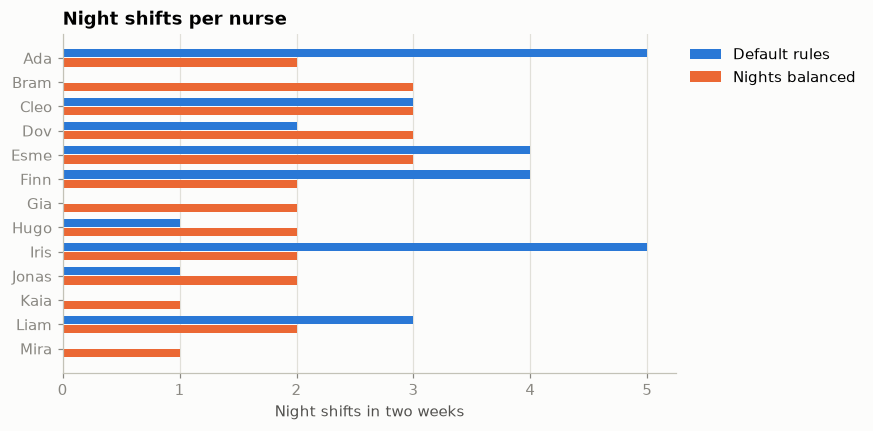

default   hard 0, nights per nurse 0 to 5, 208 h on desired days, 49 h on undesired days
balanced  hard 0, nights per nurse 1 to 3, 207 h on desired days, 53 h on undesired days


In [9]:
FAIR_NIGHTS = BalanceLocationRule(location="Night", weight=480)
fair_roster, fair_calculator = solve_roster([*RULES, FAIR_NIGHTS])


def nights(schedule):
    return (roster_grid(schedule) == SHIFT_TYPES.index("Night")).sum(axis=1)


def preference_hours(calculator):
    costs = {t["name"]: t["cost"] for t in calculator.constraint_totals()}
    return -costs["Desired day for employee"] / 60, costs["Undesired day for employee"] / 60


before, after = nights(roster), nights(fair_roster)
y = np.arange(len(nurses))
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.barh(y - 0.19, before, height=0.34, color=COLORS[0], label="Default rules")
ax.barh(y + 0.19, after, height=0.34, color=COLORS[1], label="Nights balanced")
ax.set_yticks(y, NAMES)
ax.invert_yaxis()
ax.set(title="Night shifts per nurse", xlabel="Night shifts in two weeks")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, schedule, calc, count in (("default", roster, calculator, before),
                                     ("balanced", fair_roster, fair_calculator, after)):
    desired, undesired = preference_hours(calc)
    print(f"{label:9s} hard {schedule.score.hard}, nights per nurse {count.min()} to {count.max()}, "
          f"{desired:.0f} h on desired days, {undesired:.0f} h on undesired days")

The solver runs for a fixed time, so these numbers are the best found in that time rather than proven
optima. A small difference between two runs can be search noise.

## 5. Fewer nurses

Each nurse who leaves takes 80 hours of capacity. While the remaining capacity covers the demand the
roster can stay feasible, and what shrinks is the room for preferences. Once capacity falls below the
demand no roster can keep every hard rule, and the score tells you which rules gave way. The nurses
removed here are not charge nurses, so that requirement is not what breaks.

13 nurses: capacity 130 shifts for 104 needed, hard 0, broken: {}
12 nurses: capacity 120 shifts for 104 needed, hard 0, broken: {}
11 nurses: capacity 110 shifts for 104 needed, hard 0, broken: {}
10 nurses: capacity 100 shifts for 104 needed, hard -2158, broken: {'Unavailable employee': 118, 'At least 10 hours between 2 shifts': 120, 'Max weekly minutes': 1920}


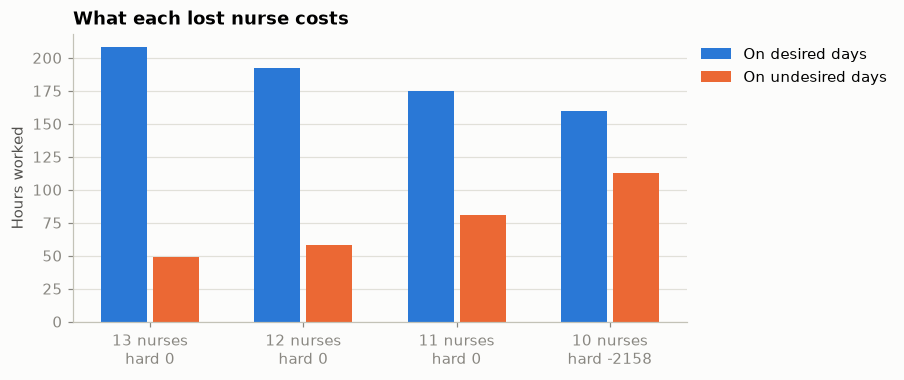

In [10]:
SHIFT_COUNT = len(make_shifts())
sizes = [13, 12, 11, 10]
desired_hours, undesired_hours, labels = [], [], []
for size in sizes:
    schedule, calc = solve_roster(RULES, staff=nurses[:size], seconds=2.0)
    desired, undesired = preference_hours(calc)
    desired_hours.append(desired)
    undesired_hours.append(undesired)
    labels.append(f"{size} nurses\nhard {schedule.score.hard}")
    broken = {t["name"]: round(t["cost"]) for t in calc.constraint_totals() if t["is_hard"] and t["cost"]}
    print(f"{size} nurses: capacity {size * 10} shifts for {SHIFT_COUNT} needed, hard {schedule.score.hard}, broken: {broken}")

x = np.arange(len(sizes))
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.bar(x - 0.17, desired_hours, width=0.3, color=COLORS[0], label="On desired days")
ax.bar(x + 0.17, undesired_hours, width=0.3, color=COLORS[1], label="On undesired days")
ax.set_xticks(x, labels)
ax.set(title="What each lost nurse costs", ylabel="Hours worked")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Read a bar group with a negative hard score carefully: soft only breaks ties between rosters with the
same hard score, so preferences on an infeasible roster are not a like-for-like comparison.

## 6. Keep searching from an earlier result

Services usually exchange JSON rather than engine objects. The pydantic models in
`optimaru.employee_scheduling.models` mirror the problem, and `solve_request` returns a
`ScheduleSolution`. `with_initial_solution` turns that answer into the start of the next search.

Change `settings.random_seed` between rounds. The same start with the same seed repeats the same
search, so a round that finds nothing leaves the next round with the identical input, and the search
is stuck for good. Below, both versions run the same number of steps per round. A step limit instead
of a clock makes each round repeatable, so any difference between the lines comes from the seeds.

A new seed can also come back empty, and that flat stretch means something else. To tell the two
apart, the dotted reference is the best of several fresh solves that share nothing with the rounds. A
line that stops well below it is stuck. A line that levels off near it has little left to find.

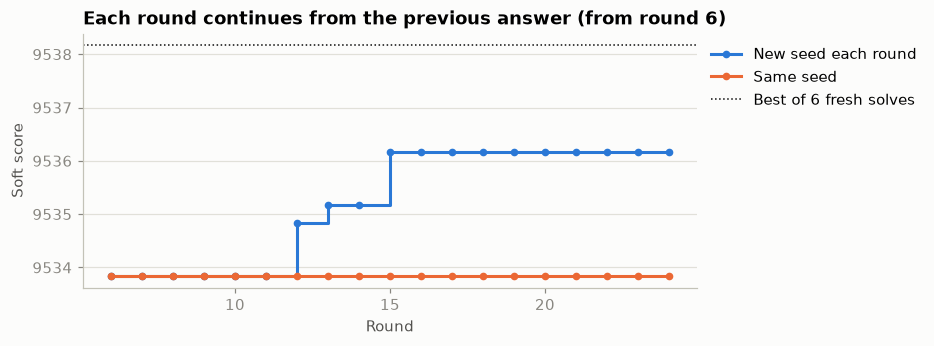

same seed: 18 of 23 rounds repeat the previous score, ends at 9533.8
new seed : 16 of 23 rounds repeat the previous score, ends at 9536.2
6 fresh solves: 9536.2 to 9538.2


In [11]:
def to_request(seed=1, rules=None, timelimit=2.0):
    workers = [
        WorkerModel(id=n.name, skills=sorted(n.skills), unavailable_dates=sorted(n.unavailable_dates),
                    undesired_dates=sorted(n.undesired_dates), desired_dates=sorted(n.desired_dates))
        for n in nurses
    ]
    slots = [ShiftModel(id=s.id, start=s.start, end=s.end, location=s.location, required_skill=s.required_skill)
             for s in make_shifts()]
    return ScheduleRequest(
        timelimit=timelimit,
        settings=SolverSettings(random_seed=seed),
        model_input=SchedulingInput(workers=workers, shifts=slots, rules=rules or RULES),
    )


def run_rounds(rounds, new_seed):
    request = to_request(timelimit=30.0)
    request.settings.step_count_limit = 20_000
    history = []
    for round_number in range(rounds):
        request.settings.random_seed = 1 + round_number if new_seed else 1
        solution = solve_request(request)
        history.append((solution.score_hard, solution.score_soft))
        request = with_initial_solution(request, solution)
    return history


ROUNDS = 24
same_seed, new_seed = run_rounds(ROUNDS, False), run_rounds(ROUNDS, True)
fresh_scores = [solve_request(to_request(seed=100 + i, timelimit=0.5)).score_soft for i in range(6)]

FIRST_SHOWN = 6  # the early rounds climb thousands of points and would hide the end of the search
fig, ax = plt.subplots(figsize=(7.2, 3))
for history, color, label in ((new_seed, COLORS[0], "New seed each round"), (same_seed, COLORS[1], "Same seed")):
    rounds = range(FIRST_SHOWN, ROUNDS + 1)
    ax.plot(rounds, [history[i - 1][1] for i in rounds], color=color, linewidth=2, marker="o", markersize=4,
            drawstyle="steps-post", label=label)
ax.axhline(max(fresh_scores), color="#0b0b0b", linewidth=1, linestyle=":", label="Best of 6 fresh solves")
ax.set(title=f"Each round continues from the previous answer (from round {FIRST_SHOWN})",
       xlabel="Round", ylabel="Soft score")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, history in (("same seed", same_seed), ("new seed ", new_seed)):
    repeats = sum(a == b for a, b in zip(history, history[1:]))
    print(f"{label}: {repeats} of {ROUNDS - 1} rounds repeat the previous score, ends at {history[-1][1]:.1f}")
print(f"6 fresh solves: {min(fresh_scores):.1f} to {max(fresh_scores):.1f}")

## 7. A nurse calls in sick

Five days in, a nurse goes on sick leave for the rest of the period. The first five days have
happened, so those shifts are pinned: `pinned=True` keeps a shift with its nurse. The remaining shifts
are free to move, but a ward does not want to rewrite everyone's plans for one absence.

The code below picks the nurse, without the charge qualification, who had the most shifts left.

In [12]:
SICK_FROM = 5
base = to_request()
first = solve_request(base)
planned = {entry.shift_id: nurse for nurse, entries in first.schedule.items() for entry in entries}
remaining = [s.id for s in base.model_input.shifts if s.start // es.MINUTES_PER_DAY >= SICK_FROM]

general = [n.name for n in nurses if "Charge" not in n.skills]
sick_nurse = max(general, key=lambda name: sum(planned[shift_id] == name for shift_id in remaining))
print(f"{sick_nurse} is off from day {SICK_FROM}, leaving {sum(planned[i] == sick_nurse for i in remaining)} shifts "
      f"to reassign out of {len(remaining)} still to come")


def after_absence(request, nurse=None):
    """A copy of `request` with the past pinned and `nurse` off from SICK_FROM on."""
    changed = request.model_copy(deep=True)
    for worker in changed.model_input.workers:
        if worker.id == nurse:
            worker.unavailable_dates = sorted({*worker.unavailable_dates, *range(SICK_FROM, DAYS)})
    for shift in changed.model_input.shifts:
        if shift.start // es.MINUTES_PER_DAY < SICK_FROM:
            shift.worker, shift.pinned = planned[shift.id], True
    changed.settings.random_seed = 2
    return changed

Finn is off from day 5, leaving 5 shifts to reassign out of 64 still to come


Pinned shifts are treated as settled history: the rule list does not judge them again. So a score
with pins is **not comparable** with a score without pins, even for the same roster, as this shows.

In [13]:
unchanged = with_initial_solution(after_absence(base), first)
unchanged.timelimit = 0
print(f"same roster, no pins : {first.score_hard} hard / {first.score_soft:.1f} soft")
rescored = solve_request(unchanged)
print(f"same roster, 5 days pinned: {rescored.score_hard} hard / {rescored.score_soft:.1f} soft")

same roster, no pins : 0 hard / 9538.2 soft
same roster, 5 days pinned: 0 hard / 5757.2 soft


That is why the comparison below counts shifts that changed hands, read from the output.

`with_initial_solution` sets a starting point and no more: local search may still move anything that
is not pinned. To ask for stability, make change cost something. `AssignmentCostRule` takes a cost
per (nurse, shift), so every shift given to someone other than its planned nurse can carry a price.

Fresh start                   hard 0, 36 shifts changed hands
Warm start                    hard 0, 36 shifts changed hands
Warm start, change costs 480  hard 0, 8 shifts changed hands


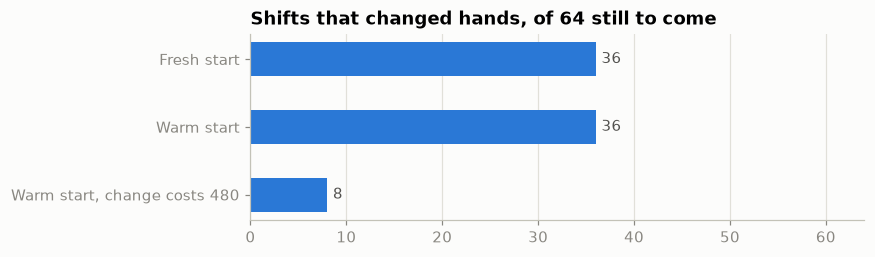

In [14]:
def changed_hands(solution):
    now = {entry.shift_id: nurse for nurse, entries in solution.schedule.items() for entry in entries}
    return sum(now.get(shift_id) != planned[shift_id] for shift_id in remaining)


fresh = after_absence(base, sick_nurse)
warm = after_absence(with_initial_solution(base, first), sick_nurse)
stable = after_absence(with_initial_solution(base, first), sick_nurse)
stable.model_input.rules.append(AssignmentCostRule(shift_costs={
    nurse.id: {shift_id: 0.0 if planned[shift_id] == nurse.id else 480.0 for shift_id in remaining}
    for nurse in stable.model_input.workers
}))

results = {}
for label, request in (("Fresh start", fresh), ("Warm start", warm), ("Warm start, change costs 480", stable)):
    request.timelimit = 1.0
    results[label] = solve_request(request)
    print(f"{label:29s} hard {results[label].score_hard}, {changed_hands(results[label])} shifts changed hands")

fig, ax = plt.subplots(figsize=(7.2, 2.2))
counts = [changed_hands(solution) for solution in results.values()]
ax.barh(list(results), counts, height=0.5, color=COLORS[0])
for row, count in enumerate(counts):
    ax.text(count + 0.6, row, str(count), va="center", color=INK)
ax.invert_yaxis()
ax.set(title=f"Shifts that changed hands, of {len(remaining)} still to come", xlim=(0, len(remaining)))
ax.grid(True, axis="x")
plt.show()

### When a hard score will not move

The nurse above could be replaced. A charge nurse may not be, and a hard score that stays below 0 can
be a fact about the data rather than a weak search. Before giving the solver more time, count.
Every day needs 3 charge nurses, one per shift type. This counts who is left on each remaining day.

In [15]:
absent = "Cleo"
leads = [n for n in nurses if "Charge" in n.skills and n.name != absent]
floor = 0
for day in range(SICK_FROM, DAYS):
    free = [n.name for n in leads if day not in n.unavailable_dates]
    if len(free) < len(SHIFT_TYPES):
        floor += len(SHIFT_TYPES) - len(free)
        print(f"day {day}: only {len(free)} charge nurses for {len(SHIFT_TYPES)} charge slots: {', '.join(free)}")

request = after_absence(with_initial_solution(base, first), absent)
request.timelimit = 1.0
solution = solve_request(request)
print(f"floor from the count alone: at least {floor} slot(s) without a qualified nurse")
print(f"solver, {absent} absent: hard {solution.score_hard}, "
      f"{[(t.name, t.cost) for t in solution.rule_totals if t.is_hard and t.cost]}")

day 12: only 2 charge nurses for 3 charge slots: Dov, Esme
floor from the count alone: at least 1 slot(s) without a qualified nurse
solver, Cleo absent: hard -2, [('Missing required skill', 2.0)]


No amount of search can beat that floor. The solver can end below it, because the count ignores rest
and weekly hours, but not above it. The fix is a staffing decision, such as lending the ward a charge
nurse for that day.

## Next steps

- The rule list above is a small part of what ships. `list_constraints()` also has minimum runs of work,
  rest after long runs, `day_pattern` for sequences such as a lone day off, `target_days_off` for
  weekends, and pay through `assignment_cost`.
- `use-cases/employee-scheduling/README.md` covers the solver options and how to add your own moves and
  constraints in C++.
- When work is a queue of tasks rather than fixed slots on a calendar, see `task-assigning.ipynb`.